# Tech Challenge Fase 1: triagem de risco de alteração glicêmica

Modelo de classificação binária com dados do BRFSS 2015 (CDC). Ele apoia um questionário
respondido pelo paciente na sala de espera. O resultado vai para o médico, que tem a palavra final.
O modelo é uma ferramenta de **triagem**, não de diagnóstico.

## 1. Problema e dados

- **Fonte:** BRFSS 2015, pesquisa telefônica autodeclarada do CDC (441.456 pessoas, 330 colunas).
- **Público do produto:** pacientes **sem** diagnóstico prévio de diabetes.
- **Alvo:** alteração glicêmica atual ou passada (diabetes, gestacional ou pré-diabetes).
- **Métrica principal:** recall da classe positiva. Um falso positivo custa uma glicemia de jejum;
  um falso negativo adia um diagnóstico.
- **Seleção de colunas:** das 330 originais ficaram 10 features. Saíram colunas administrativas,
  módulos opcionais (69–100% vazios), variáveis que só existem para quem já é diabético e variáveis
  que o paciente não saberia responder. Uma variável por tema, preferindo as calculadas pelo CDC.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter

pd.set_option("display.max_columns", None)

In [2]:
def encontrar_raiz(marcador: str = "requirements.txt") -> Path:
    """Sobe a partir do diretório atual até achar a pasta que contém o marcador."""
    atual = Path.cwd().resolve()
    for pasta in [atual, *atual.parents]:
        if (pasta / marcador).exists():
            return pasta
    raise FileNotFoundError(
        f"'{marcador}' não foi encontrado a partir de {atual}. "
        "Execute o notebook de dentro do projeto TC1."
    )


ROOT = encontrar_raiz()
XPT = ROOT / "dataset" / "raw" / "LLCP2015.XPT"
RECORTE = ROOT / "dataset" / "processed" / "brfss2015_recorte.parquet"
FIGURAS = ROOT / "reports" / "figures"
FIGURAS.mkdir(parents=True, exist_ok=True)

In [3]:
ALVO = "DIABETE3"  # 1 = sim, 2 = só na gravidez, 3 = não, 4 = pré-diabetes, 7 = não sabe, 9 = recusou

FEATURES = [
    "_AGEG5YR",  # faixas de 5 anos: 1 = 18–24 ... 13 = 80+, 14 = ausente
    "SEX",       # 1 = masculino, 2 = feminino
    "_BMI5",     # IMC com 2 casas decimais implícitas (2534 = 25,34); vazio = ausente
    "_SMOKER3",  # 1 = todo dia, 2 = alguns dias, 3 = ex-fumante, 4 = nunca fumou, 9 = ausente
    "EXERANY2",  # 1 = sim, 2 = não, 7 = não sabe, 9 = recusou (invertido em relação ao _RFDRHV5)
    "_RFDRHV5",  # bebedor pesado: 1 = não, 2 = sim, 9 = ausente
    "_RFCHOL",   # colesterol alto: 1 = não, 2 = sim, 9 = ausente, vazio = não mediu
    "_RFHYPE5",  # pressão alta: 1 = não, 2 = sim, 9 = ausente
    "GENHLTH",   # 1 = excelente ... 5 = ruim, 7 = não sabe, 9 = recusou
    "DIFFWALK",  # dificuldade para andar: 1 = sim, 2 = não, 7 = não sabe, 9 = recusou
]

## 2. Carga e primeira exploração

O XPT bruto tem 1,1 GB e fica fora do Git. Ele só é lido se o recorte ainda não existir.
O recorte tem 2 MB e fica versionado, então o notebook roda sem baixar nada.

In [4]:
if not RECORTE.exists():
    bruto = pd.read_sas(XPT, format="xport", encoding="latin-1")
    bruto[[ALVO, *FEATURES]].to_parquet(RECORTE)
    del bruto

df = pd.read_parquet(RECORTE)
df.shape

(441456, 11)

In [5]:
df.head()

,DIABETE3,_AGEG5YR,SEX,_BMI5,_SMOKER3,EXERANY2,_RFDRHV5,_RFCHOL,_RFHYPE5,GENHLTH,DIFFWALK
0,3.0,9.0,2.0,4018.0,3.0,2.0,1.0,2.0,2.0,5.0,1.0
1,3.0,7.0,2.0,2509.0,1.0,1.0,1.0,1.0,1.0,3.0,2.0
2,3.0,11.0,2.0,2204.0,9.0,NaN,9.0,2.0,1.0,4.0,NaN
3,3.0,9.0,2.0,2819.0,4.0,2.0,1.0,2.0,2.0,5.0,1.0
4,3.0,9.0,2.0,2437.0,4.0,2.0,1.0,1.0,1.0,5.0,2.0


In [6]:
pd.DataFrame({
    "dtype": df.dtypes,
    "pct_nulos": (df.isnull().mean() * 100).round(2),
    "n_unicos": df.nunique(),
})

,dtype,pct_nulos,n_unicos
DIABETE3,float64,0.00,6
_AGEG5YR,float64,0.00,14
SEX,float64,0.00,2
_BMI5,float64,8.24,3736
_SMOKER3,float64,0.00,5
EXERANY2,float64,8.03,4
_RFDRHV5,float64,0.00,3
_RFCHOL,float64,13.40,3
_RFHYPE5,float64,0.00,3
GENHLTH,float64,0.00,7


**Cuidado:** `pct_nulos` subestima os ausentes. Várias colunas usam códigos (7, 9, 14) em vez de
célula vazia, e esses códigos só viram ausentes na limpeza.

Um caso oposto apareceu na seleção. Comecei com a `SMOKDAY2`, mas ela é uma pergunta de seguimento,
feita só a quem respondeu sim na `SMOKE100`. Filtrar os vazios eliminaria quem nunca fumou, mais da
metade da base. Por isso usei a `_SMOKER3`, que combina as duas perguntas numa variável calculada.

In [7]:
df[ALVO].value_counts(dropna=False)

DIABETE3
3.0    372104
1.0     57256
4.0      7690
2.0      3608
7.0       598
9.0       193
NaN         7
Name: count, dtype: int64

## 3. Limpeza

Só recodificação: os ausentes ficam como NaN e quem os preenche é o pipeline da seção 6, ajustado no
treino, para não vazar informação da validação e do teste.

- **Alvo:** as linhas sem rótulo (NaN, 7 e 9, ~0,2%) saem. Positivo = códigos 1, 2 e 4; negativo = 3.
- **Códigos especiais:** "não sabe", "recusou" e "ausente" viram NaN.
- **`_RFCHOL`:** o vazio vira a categoria 3 ("não mediu"), porque é uma resposta e não um dado faltante.
- **`_BMI5`:** dividido por 100, pois o CDC grava o IMC com 2 casas implícitas.

In [8]:

dados = df[df[ALVO].isin([1, 2, 3, 4])].copy()
dados["alvo"] = dados[ALVO].isin([1, 2, 4]).astype(int)
dados = dados.drop(columns=ALVO)

# O vazio precisa virar categoria ANTES de o 9 virar NaN, senão os dois se misturam
dados["_RFCHOL"] = dados["_RFCHOL"].fillna(3)

CODIGOS_AUSENTES = {
    "_AGEG5YR": [14],
    "_SMOKER3": [9],
    "_RFDRHV5": [9],
    "_RFHYPE5": [9],
    "_RFCHOL": [9],
    "EXERANY2": [7, 9],
    "GENHLTH": [7, 9],
    "DIFFWALK": [7, 9],
}
for coluna, codigos in CODIGOS_AUSENTES.items():
    dados[coluna] = dados[coluna].replace(codigos, np.nan)

dados["_BMI5"] = dados["_BMI5"] / 100

print(f"Linhas: {len(dados):,} | Prevalência do alvo: {dados['alvo'].mean():.1%}")
print(f"IMC acima de 70 (provável erro de autodeclaração): {(dados['_BMI5'] > 70).sum()}")
(dados.isnull().mean() * 100).round(2).sort_values(ascending=False)


Linhas: 440,658 | Prevalência do alvo: 15.6%
IMC acima de 70 (provável erro de autodeclaração): 1034


EXERANY2    8.59
_BMI5       8.21
_RFDRHV5    5.81
_SMOKER3    4.06
DIFFWALK    3.29
_AGEG5YR    1.19
_RFCHOL     0.79
_RFHYPE5    0.29
GENHLTH     0.28
SEX         0.00
alvo        0.00
dtype: float64

**Resultado.** Restam 440.658 pessoas, com prevalência de 15,6%. Depois da recodificação aparecem
ausentes que o `pct_nulos` da seção 2 escondia, como os 5,8% do `_RFDRHV5`, antes em 0%.

Os 1.034 casos com IMC acima de 70 (0,2%) foram mantidos. São provavelmente erros de autodeclaração,
mas o CDC os considera válidos e não há critério objetivo para o corte.

## 4. Análise exploratória

In [9]:

import seaborn as sns

dados.describe().round(2)


,_AGEG5YR,SEX,_BMI5,_SMOKER3,EXERANY2,_RFDRHV5,_RFCHOL,_RFHYPE5,GENHLTH,DIFFWALK,alvo
count,435424.00,440658.00,404467.00,422770.00,402808.00,415063.00,437182.00,439400.00,439429.00,426155.00,440658.00
mean,7.73,1.58,28.04,3.32,1.27,1.05,1.63,1.40,2.56,1.83,0.16
std,3.45,0.49,6.65,0.96,0.44,0.22,0.71,0.49,1.08,0.38,0.36
min,1.00,1.00,12.02,1.00,1.00,1.00,1.00,1.00,1.00,1.00,0.00
25%,5.00,1.00,23.73,3.00,1.00,1.00,1.00,1.00,2.00,2.00,0.00
50%,8.00,2.00,26.95,4.00,1.00,1.00,2.00,1.00,2.00,2.00,0.00
75%,10.00,2.00,30.90,4.00,2.00,1.00,2.00,2.00,3.00,2.00,0.00
max,13.00,2.00,99.95,4.00,2.00,2.00,3.00,2.00,5.00,2.00,1.00


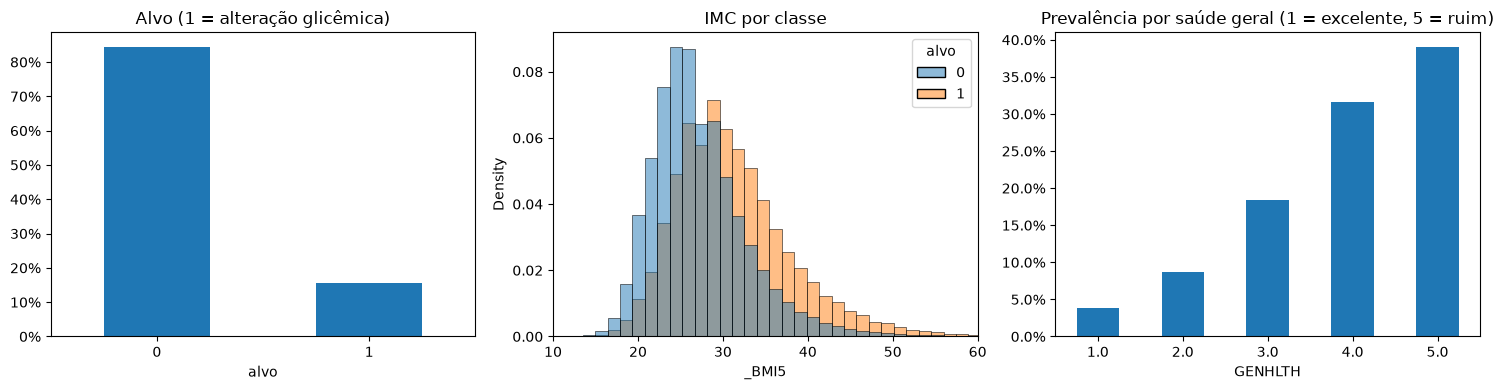

In [10]:

fig, eixos = plt.subplots(1, 3, figsize=(15, 4))
dados["alvo"].value_counts(normalize=True).sort_index().plot(kind="bar", ax=eixos[0], rot=0)
eixos[0].set_title("Alvo (1 = alteração glicêmica)")
eixos[0].yaxis.set_major_formatter(PercentFormatter(1.0))
eixos[0].set_ylabel("")
sns.histplot(data=dados, x="_BMI5", hue="alvo", bins=60, stat="density", common_norm=False, ax=eixos[1])
eixos[1].set_xlim(10, 60)
eixos[1].set_title("IMC por classe")
dados.groupby("GENHLTH")["alvo"].mean().plot(kind="bar", ax=eixos[2], rot=0)
eixos[2].yaxis.set_major_formatter(PercentFormatter(1.0))
eixos[2].set_title("Prevalência por saúde geral (1 = excelente, 5 = ruim)")
plt.tight_layout()
plt.savefig(FIGURAS / "distribuicoes.png", dpi=150, bbox_inches="tight")
plt.show()


**Distribuições.** O alvo é desbalanceado (84% contra 16%), então a accuracy sozinha engana. O IMC das
pessoas com alteração glicêmica está deslocado para valores mais altos, e a prevalência sobe de forma
contínua com a piora da saúde geral autodeclarada, de cerca de 4% para 39%.

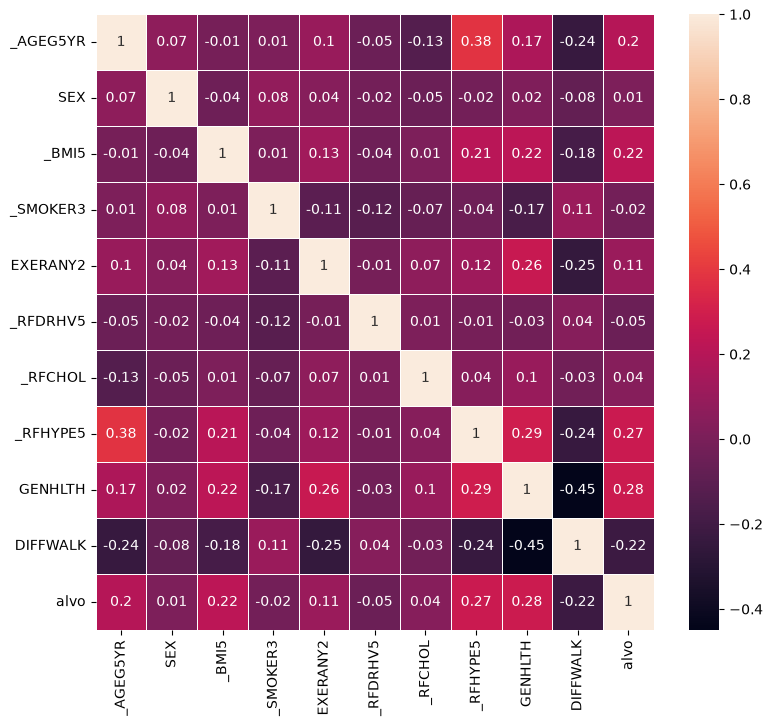

alvo        1.00
GENHLTH     0.28
_RFHYPE5    0.27
_BMI5       0.22
_AGEG5YR    0.20
EXERANY2    0.11
_RFCHOL     0.04
SEX         0.01
_SMOKER3   -0.02
_RFDRHV5   -0.05
DIFFWALK   -0.22
Name: alvo, dtype: float64

In [11]:

correlacao = dados.corr().round(2)

fig, ax = plt.subplots(figsize=(9, 8))
sns.heatmap(correlacao, annot=True, linewidths=0.5, ax=ax)
plt.savefig(FIGURAS / "correlacao.png", dpi=150, bbox_inches="tight")
plt.show()

correlacao["alvo"].sort_values(ascending=False)


**Correlação.** As maiores associações lineares com o alvo são saúde geral (0,28), pressão alta (0,27),
IMC (0,22) e idade (0,20). A `DIFFWALK` tem −0,22 só porque nela 1 = sim. A correlação é apenas um
indicativo: várias colunas são códigos categóricos, e a de fumo (−0,02) não mede bem uma variável sem
ordem natural. Nenhum par de features é tão correlacionado que justifique remover uma delas.

### Descoberta: os hábitos e o momento do diagnóstico

O BRFSS retrata o hábito **atual**, e o diagnóstico pode ter acontecido anos antes. As análises abaixo
comparam a prevalência do alvo dentro de cada faixa etária, para separar o efeito da idade.

In [12]:
FAIXAS = ["18–24", "25–29", "30–34", "35–39", "40–44", "45–49", "50–54",
          "55–59", "60–64", "65–69", "70–74", "75–79", "80+"]  # códigos 1 a 13 do _AGEG5YR


def prevalencia_por_idade(df, coluna, validos, rotulos):
    """Prevalência do alvo por faixa etária e pelos grupos de `coluna`.

    validos: códigos da coluna que entram (ex.: [1, 2])
    rotulos: nomes dos grupos, NA ORDEM dos códigos (ex.: ["Sim", "Não"])
    """
    d = df[[ALVO, "_AGEG5YR", coluna]].copy()
    d = d[d[ALVO].isin([1, 2, 3, 4])]
    d["alvo"] = d[ALVO].isin([1, 2, 4]).astype(int)
    d = d[d[coluna].isin(validos)]
    d = d[d["_AGEG5YR"].isin(range(1, 14))]

    tab = d.groupby(["_AGEG5YR", coluna])["alvo"].mean().unstack()
    tab.columns = rotulos
    return tab


def plot_prevalencia_por_idade(tab, titulo, arquivo):
    """Plota a tabela de `prevalencia_por_idade` e salva a figura em reports/figures."""
    ax = tab.plot(marker="o", figsize=(9, 5))
    ax.set_xticks(range(1, 14))  # o índice da tabela são os próprios códigos 1 a 13
    ax.set_xticklabels(FAIXAS, rotation=45)
    ax.yaxis.set_major_formatter(PercentFormatter(1.0))
    ax.set_xlabel("Faixa etária")
    ax.set_ylabel("Prevalência de alteração glicêmica")
    ax.set_title(titulo)
    ax.grid(alpha=0.3)
    plt.savefig(FIGURAS / arquivo, dpi=150, bbox_inches="tight")
    plt.show()

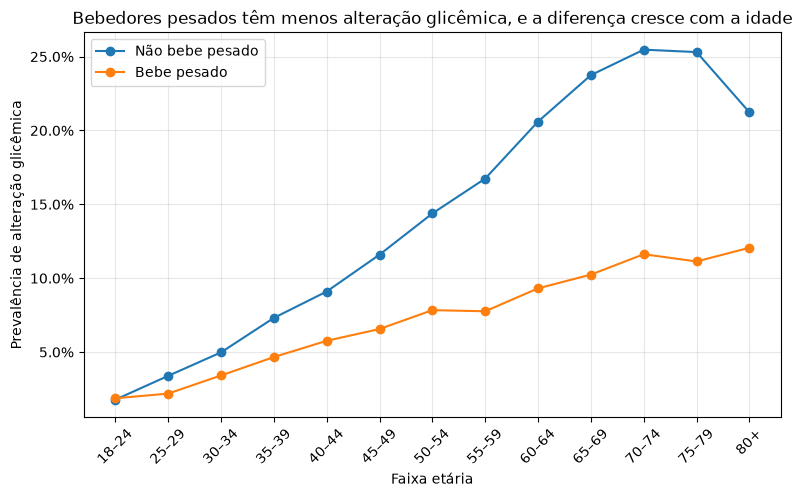

,Não bebe pesado,Bebe pesado
_AGEG5YR,,
1.0,0.018,0.019
2.0,0.034,0.022
3.0,0.050,0.034
4.0,0.073,0.047
5.0,0.091,0.058
6.0,0.116,0.066
7.0,0.144,0.078
8.0,0.167,0.078
9.0,0.206,0.093


In [13]:
tab_alcool = prevalencia_por_idade(df, "_RFDRHV5", [1, 2], ["Não bebe pesado", "Bebe pesado"])
plot_prevalencia_por_idade(
    tab_alcool,
    "Bebedores pesados têm menos alteração glicêmica, e a diferença cresce com a idade",
    "alcool_vs_idade.png",
)
tab_alcool.round(3)

**Álcool.** Ao contrário do esperado, bebedores pesados têm menos da metade da prevalência (7,4% contra
16,2%). A diferença persiste dentro das faixas etárias, exceto aos 18–24 anos, quando os grupos são
iguais (1,8% e 1,9%), e cresce com a idade. O padrão é coerente com a **causalidade reversa**: quem
recebe o diagnóstico tende a mudar de hábito. É uma hipótese, porque o dado é uma foto de um único
momento e não permite comprová-la.

A idade está muito mais associada ao alvo (1,8% → 25%) do que o álcool (até ~2,3× dentro da mesma faixa,
e só 5% da população). Hipótese a verificar com o SHAP na seção 9.

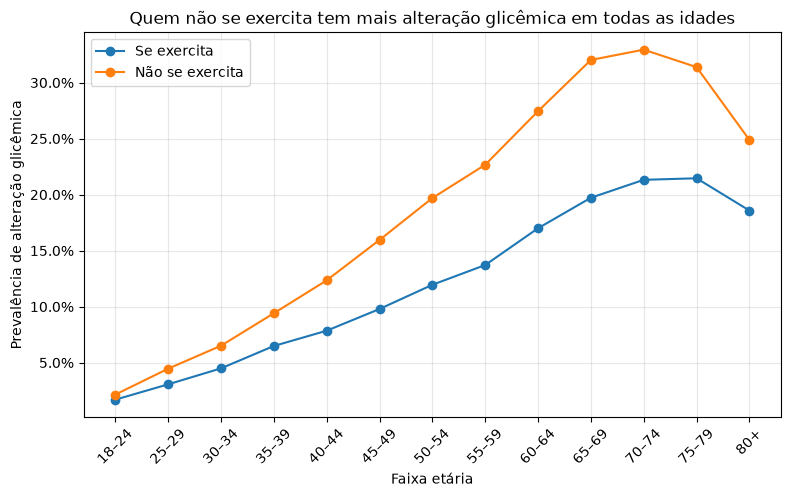

,Se exercita,Não se exercita
_AGEG5YR,,
1.0,0.017,0.021
2.0,0.031,0.045
3.0,0.045,0.065
4.0,0.065,0.094
5.0,0.079,0.123
6.0,0.098,0.160
7.0,0.120,0.197
8.0,0.137,0.227
9.0,0.170,0.274


In [14]:
tab_exercicio = prevalencia_por_idade(df, "EXERANY2", [1, 2], ["Se exercita", "Não se exercita"])
plot_prevalencia_por_idade(
    tab_exercicio,
    "Quem não se exercita tem mais alteração glicêmica em todas as idades",
    "exercicio_vs_idade.png",
)
tab_exercicio.round(3)

**Exercício.** Aqui o resultado confirma o esperado, em todas as faixas. No início da idade adulta a
diferença é pequena, mas já existe (1,7% e 2,1%), e aumenta à medida que a idade avança. Diferente do
álcool, ela aparece antes de os diagnósticos se acumularem.

**Consequência para o modelo.** O treino retrata muitos diabéticos **depois** do diagnóstico, mas o
produto atende quem **ainda não** foi diagnosticado. Isso é uma limitação documentada: o efeito das
variáveis de hábito deve ser lido como associação, nunca como causa.

## 5. Separação treino, validação e teste

60/20/20 estratificado, antes de qualquer transformação que aprenda dos dados. A validação escolhe o
modelo e o limiar. O teste só é usado na avaliação final.

In [15]:

from sklearn.model_selection import train_test_split

X = dados.drop(columns="alvo")
y = dados["alvo"]

X_resto, X_teste, y_resto, y_teste = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
X_treino, X_val, y_treino, y_val = train_test_split(
    X_resto, y_resto, test_size=0.25, stratify=y_resto, random_state=42  # 25% de 80% = 20% do total
)

print(f"Treino: {len(X_treino):,} | Validação: {len(X_val):,} | Teste: {len(X_teste):,}")
print(f"Prevalência: {y_treino.mean():.3f} | {y_val.mean():.3f} | {y_teste.mean():.3f}")


Treino: 264,394 | Validação: 88,132 | Teste: 88,132
Prevalência: 0.156 | 0.156 | 0.156


## 6. Pipeline de pré-processamento

- **Numéricas e ordinais** (IMC, faixa etária, saúde geral): mediana + `StandardScaler`.
- **Categóricas** (as demais): valor mais frequente + `OneHotEncoder`. Os códigos não têm ordem:
  "fumante = 3" não é "três vezes" "fumante = 1".

In [16]:

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

NUMERICAS = ["_BMI5", "_AGEG5YR", "GENHLTH"]
CATEGORICAS = ["SEX", "_SMOKER3", "EXERANY2", "_RFDRHV5", "_RFCHOL", "_RFHYPE5", "DIFFWALK"]

pipeline_num = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
pipeline_cat = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])
preprocessador = ColumnTransformer([
    ("num", pipeline_num, NUMERICAS),
    ("cat", pipeline_cat, CATEGORICAS),
])


## 7. Modelos

Baseline trivial e três modelos com `class_weight="balanced"`, que trata o desbalanceamento só no
treino. **Regra definida antes de comparar:** vence a maior AUC na validação, porque ela não depende
do limiar, que é escolhido depois.

In [17]:

from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.tree import DecisionTreeClassifier

classificadores = {
    "Baseline (classe majoritária)": DummyClassifier(strategy="most_frequent"),
    "Regressão Logística": LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42),
    "Árvore de Decisão": DecisionTreeClassifier(
        max_depth=8, min_samples_leaf=50, class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=12, min_samples_leaf=20,
        class_weight="balanced", n_jobs=-1, random_state=42,
    ),
}

modelos, linhas = {}, []
for nome, classificador in classificadores.items():
    modelo = Pipeline([("pre", preprocessador), ("clf", classificador)]).fit(X_treino, y_treino)
    modelos[nome] = modelo
    pred = modelo.predict(X_val)
    linhas.append({
        "modelo": nome,
        "recall": recall_score(y_val, pred),
        "precisão": precision_score(y_val, pred, zero_division=0),
        "f1": f1_score(y_val, pred),
        "accuracy": accuracy_score(y_val, pred),
        "auc": roc_auc_score(y_val, modelo.predict_proba(X_val)[:, 1]),
    })

comparacao = pd.DataFrame(linhas).set_index("modelo").round(3)
melhor_nome = comparacao["auc"].idxmax()
melhor = modelos[melhor_nome]
print("Modelo escolhido:", melhor_nome)
comparacao


Modelo escolhido: Random Forest


,recall,precisão,f1,accuracy,auc
modelo,,,,,
Baseline (classe majoritária),0.000,0.000,0.000,0.844,0.500
Regressão Logística,0.754,0.325,0.454,0.718,0.804
Árvore de Decisão,0.751,0.323,0.452,0.716,0.805
Random Forest,0.760,0.327,0.458,0.720,0.811


**Comparação na validação.** O baseline tem 84,4% de accuracy e recall **zero**, o que mostra por que a
accuracy não serve como métrica principal. Os três modelos ficam muito próximos (AUC de 0,804 a 0,811).
O Random Forest venceu pela regra, com pouca vantagem: o limite do resultado parece vir mais das
informações disponíveis do que da escolha do algoritmo.

## 8. Limiar e avaliação final

**Regra definida antes de olhar o teste:** o limiar mais alto que mantém recall de pelo menos 80% na
validação. Isso prioriza não deixar passar quem tem alteração glicêmica, sem encaminhar mais gente do
que o necessário para atingir essa meta. O teste é usado uma única vez, com o modelo e o limiar já fixos.

In [18]:

from sklearn.metrics import ConfusionMatrixDisplay, classification_report, precision_recall_curve

RECALL_MINIMO = 0.80

precisoes, recalls, limiares = precision_recall_curve(y_val, melhor.predict_proba(X_val)[:, 1])
limiar = limiares[recalls[:-1] >= RECALL_MINIMO].max()
print(f"Limiar escolhido na validação: {limiar:.3f}")


Limiar escolhido na validação: 0.461


               precision    recall  f1-score   support

Sem alteração      0.946     0.668     0.784     74421
Com alteração      0.306     0.795     0.442     13711

     accuracy                          0.688     88132
    macro avg      0.626     0.732     0.613     88132
 weighted avg      0.847     0.688     0.730     88132

Accuracy: 0.688 | AUC: 0.807
Pacientes encaminhados para exame: 40.4%


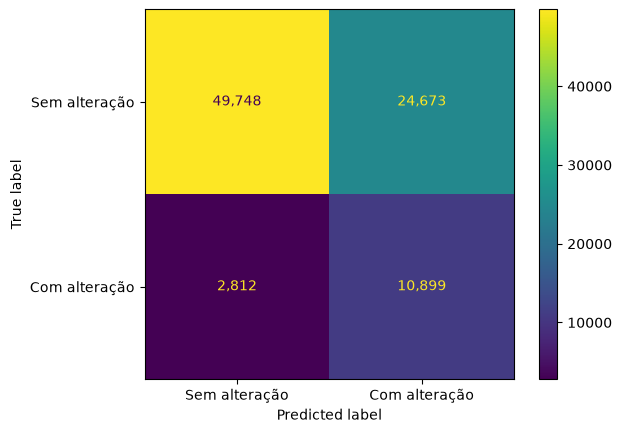

In [19]:

prob_teste = melhor.predict_proba(X_teste)[:, 1]
pred_teste = (prob_teste >= limiar).astype(int)

print(classification_report(y_teste, pred_teste, target_names=["Sem alteração", "Com alteração"], digits=3))
print(f"Accuracy: {accuracy_score(y_teste, pred_teste):.3f} | AUC: {roc_auc_score(y_teste, prob_teste):.3f}")
print(f"Pacientes encaminhados para exame: {pred_teste.mean():.1%}")

ConfusionMatrixDisplay.from_predictions(
    y_teste, pred_teste, display_labels=["Sem alteração", "Com alteração"], values_format=",d"
)
plt.savefig(FIGURAS / "matriz_confusao.png", dpi=150, bbox_inches="tight")
plt.show()


In [20]:

# Recall por tipo de positivo: o alvo amplo pode esconder diferenças entre os grupos
codigo = df.loc[X_teste.index, ALVO]
nomes = {1.0: "Diabetes", 2.0: "Só na gravidez", 4.0: "Pré-diabetes"}
recall_por_codigo = pd.DataFrame({
    nomes[c]: {"pessoas": (codigo == c).sum(), "% sinalizadas": pred_teste[codigo == c].mean()}
    for c in nomes
}).T

# Métricas por sexo: verificação de viés
sexo = X_teste["SEX"].map({1.0: "Masculino", 2.0: "Feminino"})
por_sexo = pd.DataFrame({
    s: {
        "prevalência": y_teste[sexo == s].mean(),
        "recall": recall_score(y_teste[sexo == s], pred_teste[sexo == s]),
        "precisão": precision_score(y_teste[sexo == s], pred_teste[sexo == s]),
        "% encaminhados": pred_teste[sexo == s].mean(),
    }
    for s in ["Masculino", "Feminino"]
}).T

display(recall_por_codigo.round(3))
display(por_sexo.round(3))


,pessoas,% sinalizadas
Diabetes,11472.0,0.836
Só na gravidez,727.0,0.303
Pré-diabetes,1512.0,0.720


,prevalência,recall,precisão,% encaminhados
Masculino,0.153,0.811,0.310,0.401
Feminino,0.157,0.783,0.304,0.405


**Resultado no teste.** Recall de 79,5%, precisão de 30,6%, F1 de 0,442, accuracy de 68,8% e AUC de 0,807,
encaminhando 40,4% dos pacientes. O recall ficou um pouco abaixo da meta de 80% da validação. Isso é uma
variação esperada, e o limiar **não** foi reajustado, para o teste continuar sendo uma medida honesta.

De cada 100 pacientes encaminhados, cerca de 31 têm alteração glicêmica, o dobro da prevalência da base.
O custo é aceitável apenas porque o falso positivo aqui significa um exame simples.

- **Por tipo de positivo:** o modelo sinaliza 83,6% dos diabéticos e 72,0% dos pré-diabéticos, mas só
  **30,3%** dos casos de diabetes gestacional, menos que os 40,4% da base geral. As features não captam
  esse histórico, e na prática o modelo não cumpre o objetivo de sinalizar esse grupo.
- **Por sexo:** as métricas são próximas (recall de 81,1% nos homens e 78,3% nas mulheres; precisão de
  31,0% e 30,4%), sem sinal de distorção relevante.

## 9. Interpretação

A feature importance mostra o peso global das variáveis no Random Forest. O SHAP mostra também a
**direção** do efeito. Por custo de cálculo, ele usa uma amostra de 1.000 pessoas da validação.

/home/nando-gamba/Fontes/FFIAP/TC1/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


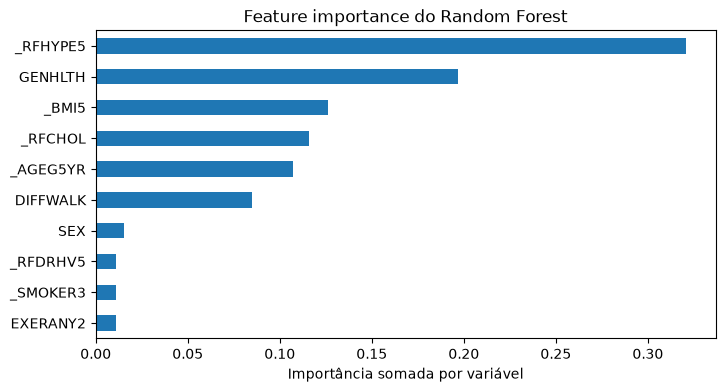

In [21]:

import shap

nomes_features = melhor["pre"].get_feature_names_out()


def variavel_original(nome):
    """'cat___SMOKER3_1.0' → '_SMOKER3'; 'num___BMI5' → '_BMI5'."""
    return nome[5:] if nome.startswith("num__") else nome[5:].rsplit("_", 1)[0]


importancia = (
    pd.Series(melhor["clf"].feature_importances_, index=nomes_features)
    .groupby(variavel_original).sum().sort_values()
)
ax = importancia.plot(kind="barh", figsize=(8, 4), title="Feature importance do Random Forest")
ax.set_xlabel("Importância somada por variável")
plt.savefig(FIGURAS / "feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()


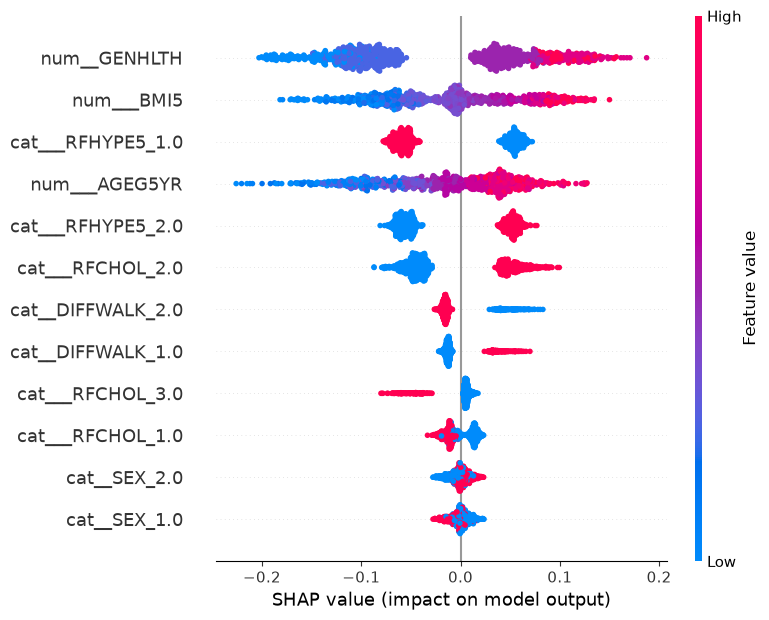

In [22]:

amostra = X_val.sample(1000, random_state=42)
amostra_transf = pd.DataFrame(melhor["pre"].transform(amostra), columns=nomes_features, index=amostra.index)

valores_shap = shap.TreeExplainer(melhor["clf"]).shap_values(amostra_transf)[:, :, 1]  # classe positiva

shap.summary_plot(valores_shap, amostra_transf, show=False, max_display=12)
plt.savefig(FIGURAS / "shap_resumo.png", dpi=150, bbox_inches="tight")
plt.show()


In [23]:

shap_abs = pd.Series(np.abs(valores_shap).mean(axis=0), index=nomes_features)
display(shap_abs.groupby(variavel_original).sum().sort_values(ascending=False).round(4).to_frame("|SHAP| médio"))

# Direção do efeito dos hábitos: SHAP médio de quem tem cada resposta
habitos = {
    "Bebedor pesado": ("_RFDRHV5", 2.0, "cat___RFDRHV5_2.0"),
    "Não bebedor pesado": ("_RFDRHV5", 1.0, "cat___RFDRHV5_1.0"),
    "Se exercita": ("EXERANY2", 1.0, "cat__EXERANY2_1.0"),
    "Não se exercita": ("EXERANY2", 2.0, "cat__EXERANY2_2.0"),
}
pd.Series({
    grupo: valores_shap[amostra[coluna] == codigo, list(nomes_features).index(nome)].mean()
    for grupo, (coluna, codigo, nome) in habitos.items()
}).round(4).to_frame("SHAP médio da variável")


,|SHAP| médio
_RFHYPE5,0.1121
GENHLTH,0.0895
_RFCHOL,0.0741
_BMI5,0.0582
_AGEG5YR,0.0552
DIFFWALK,0.0391
SEX,0.0131
EXERANY2,0.0103
_RFDRHV5,0.0077
_SMOKER3,0.0075


,SHAP médio da variável
Bebedor pesado,-0.0419
Não bebedor pesado,0.0021
Se exercita,-0.0038
Não se exercita,0.0096


**Interpretação.** A hipótese da seção 4 se confirmou: a idade pesa bem mais que o álcool (|SHAP| de
0,055 contra 0,008). Mas ela não lidera: pressão alta, saúde geral e colesterol vêm antes. A soma por
variável junta as colunas do one-hot, então essa ordem é aproximada.

O modelo também aprendeu o efeito previsto para o álcool: **ser bebedor pesado reduz o risco estimado**
(SHAP médio de −0,042). Esse é o padrão provavelmente causado pela causalidade reversa, e não deve ser
lido como efeito protetor. Na mesma linha, "nunca mediu o colesterol" reduz o risco estimado, o que pode
refletir menos acesso ao diagnóstico, e não menos doença.

## 10. Discussão crítica

**O modelo pode ser usado na prática?** Como apoio à triagem e com ressalvas; ainda não em produção.

**Como seria o uso.** O paciente sem diagnóstico prévio responde ao questionário na sala de espera. O
sistema calcula o IMC a partir do peso e da altura, e o médico recebe a sinalização e os fatores que mais
pesaram. **O médico tem sempre a palavra final**, e a confirmação vem de um exame como a glicemia de jejum.

**Limitações:**

1. **O público de uso não foi avaliado.** O teste mede a capacidade de reconhecer pessoas que **já sabem**
   da sua condição. Não há evidência direta de que o modelo encontre quem ainda não foi diagnosticado.
   Antes de qualquer uso, seria preciso um estudo com exame de glicemia em pacientes reais.
2. **Causalidade reversa.** Muitos positivos responderam depois do diagnóstico, possivelmente com hábitos
   já alterados. Os efeitos de hábitos são associações, nunca causas.
3. **Alvo autodeclarado e amplo.** Diabéticos sem diagnóstico aparecem como negativos, e o alvo inclui
   pré-diabetes e histórico gestacional, grupo que o modelo praticamente não sinaliza.
4. **Mudança de população.** O BRFSS descreve adultos dos EUA em 2015 em uma pesquisa telefônica. Uma sala
   de espera, especialmente em outro país, é outra população, e os pesos amostrais não foram usados.
5. **Carga operacional.** Encaminhar 40% dos pacientes pode ser excessivo para algumas clínicas. O limiar
   pode ser ajustado, ao custo de perder casos.

**Próximos passos.** Validar com exames reais, reavaliar o tratamento do código gestacional e calibrar
as probabilidades, caso se queira exibir um risco numérico ao médico.